In [1]:
%pip install opencv-python numpy


[notice] A new release of pip is available: 23.2.1 -> 23.3.1
[notice] To update, run: python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


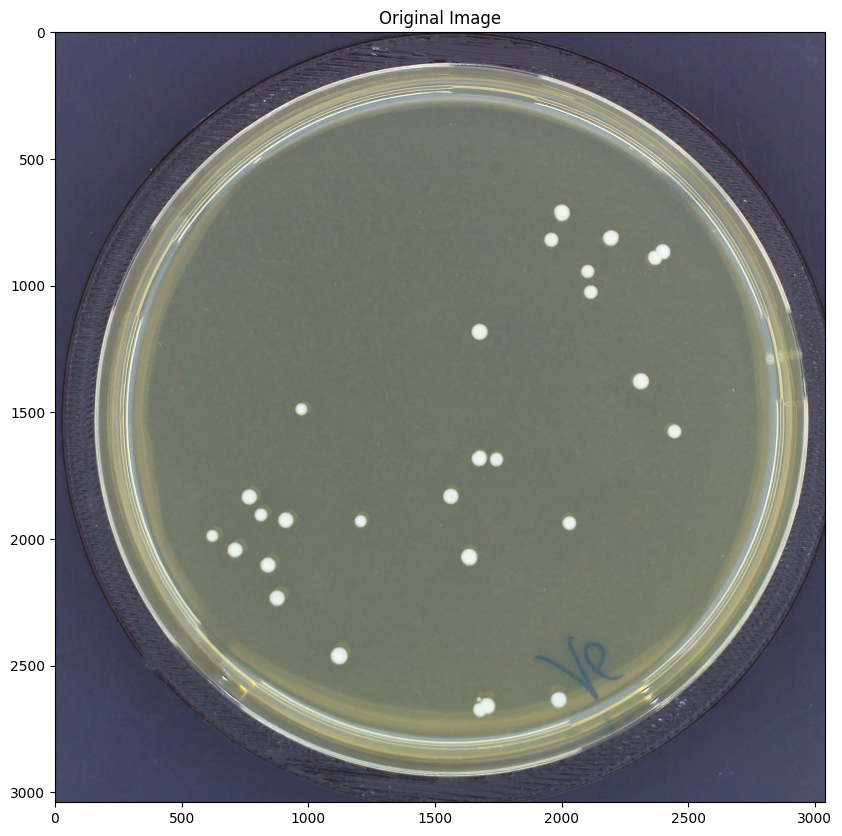

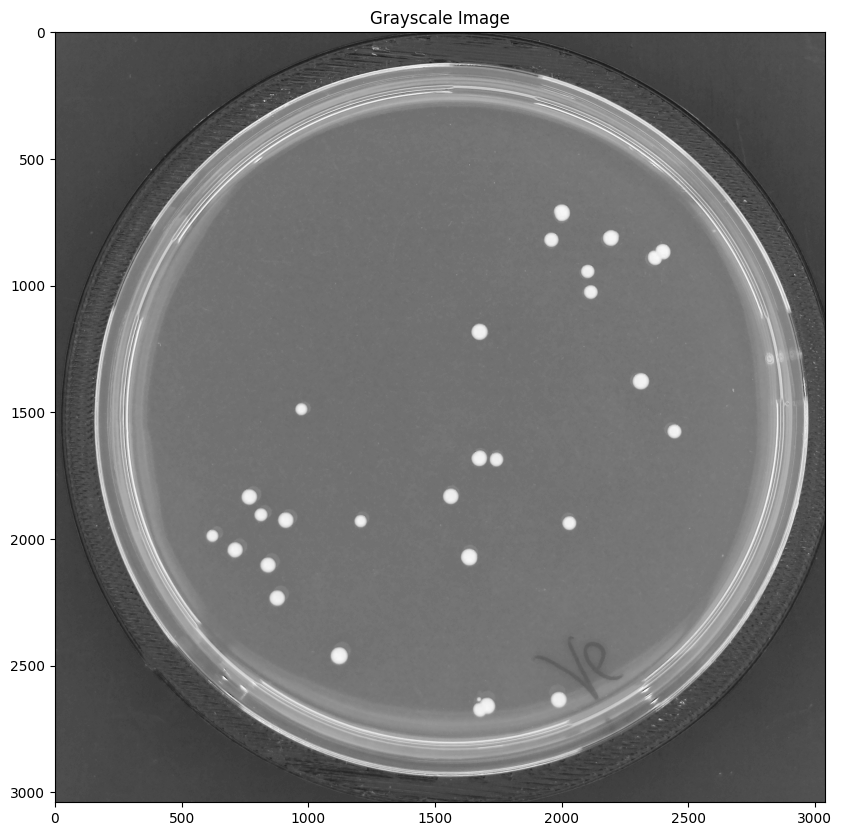

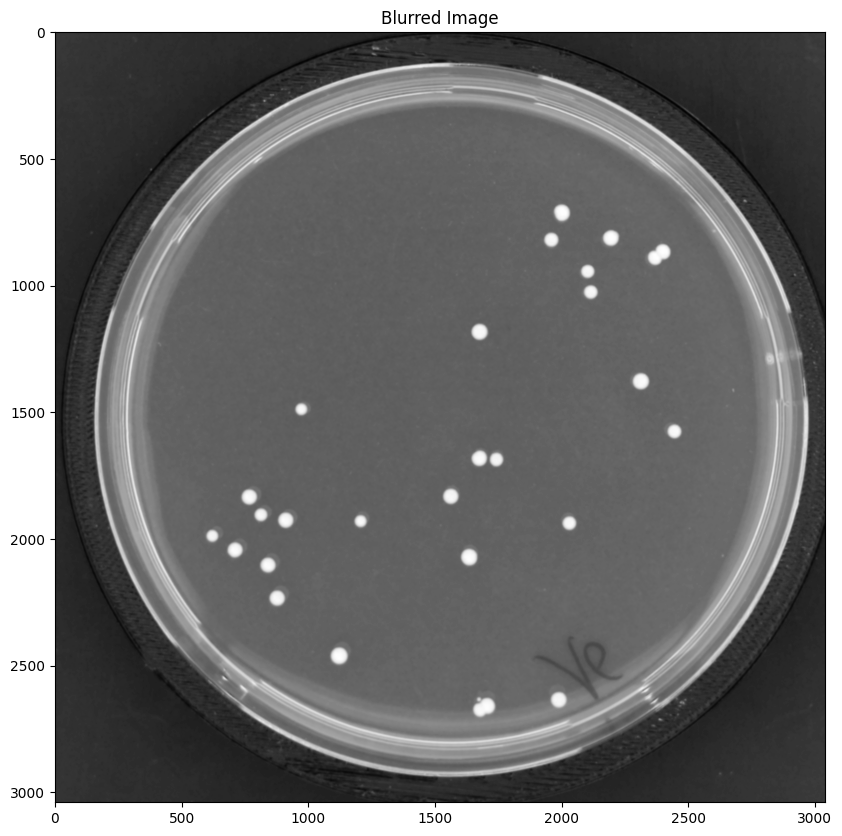

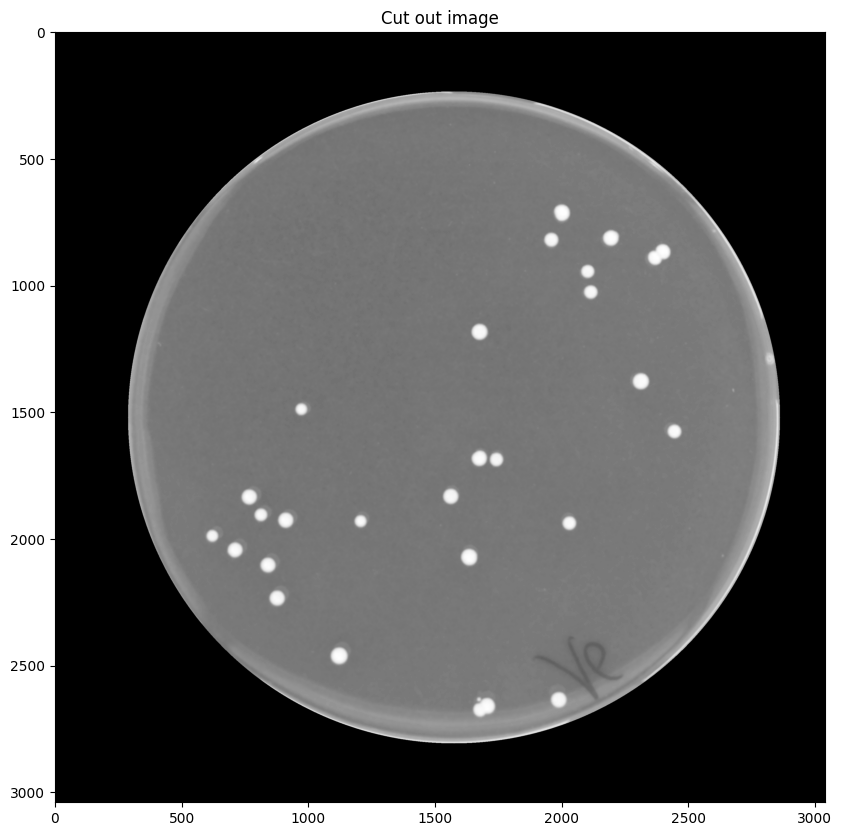

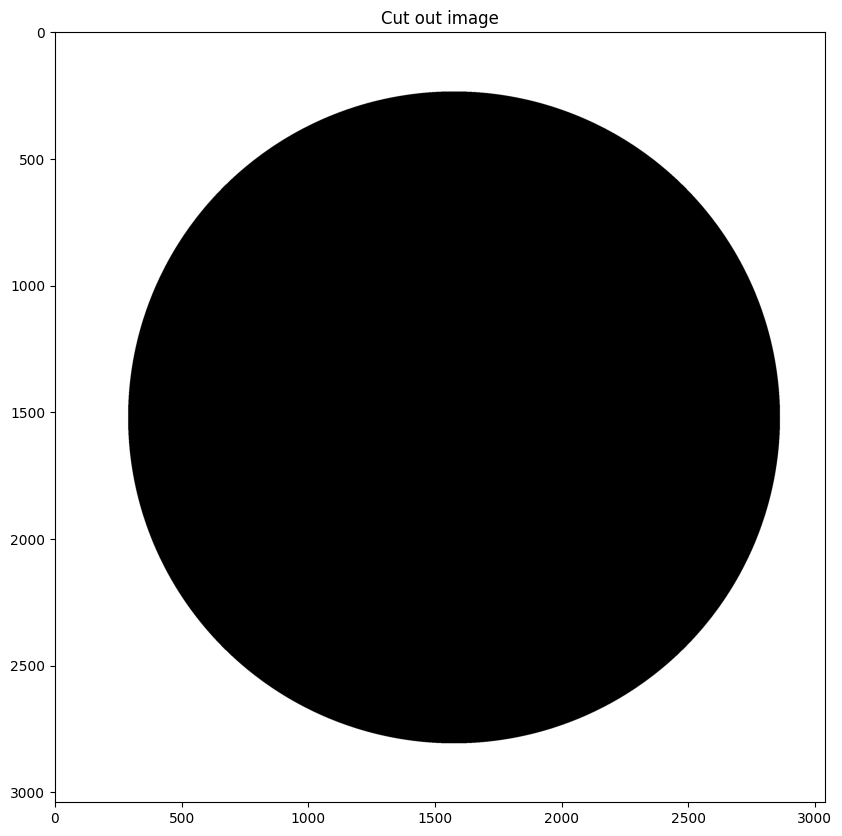

([1], ['thresholded/thresholded_0.png'])

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# Load images
image_paths = [
    "../data/counted/cocci_lactococcus_raffinolactis_16_default_mmrsagar_3_07102022160652.jpg",
]


# Define a function to process the images and count colonies
def count_colonies(image_path, debug=False):
    # Read the image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)

    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title("Original Image")
        plt.show()

    height, width, channels = img.shape

    # Convert the image to grayscale for processing
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(gray, cmap="gray")
        plt.title("Grayscale Image")
        plt.show()

    # Use Gaussian blur to reduce noise and improve circle detection
    blurred = cv2.GaussianBlur(
        gray,
        (15, 15),
        0,
    )
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Blurred Image")
        plt.show()

    # Hough Circle detection
    outer_circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=6,
        minDist=30,
        param1=150,
        param2=10,
        # Circle should be large, but not larger than the image.
        minRadius=round(max(height, width) / 3),
        maxRadius=round(max(height, width) / 2),
    )

    if outer_circles is not None:
        # Convert circles to expected format
        outer_circles = np.uint16(np.around(outer_circles))

        # Create a black mask
        mask = np.zeros_like(gray)

        # Get the (x, y) coordinate and the radius of the circle
        x, y, r = outer_circles[0][0]
        # r = r - 10  # Subtracting a value to remove the plastic border

        # Draw the circle in the mask
        cv2.circle(mask, (x, y), r, (255, 255, 255), -1)

        # Bitwise the image with mask
        result = cv2.bitwise_and(blurred, blurred, mask=mask)

        blurred = result

    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Cut out image")
        plt.show()

    # Perform Otsu's thresholding
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Find contours which correspond to colonies
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Count the number of contours found
    colony_count = len(contours)

    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(thresh, cmap="gray")
        plt.title("Cut out image")
        plt.show()

    # Return the thresholded image and the count of bacteria colonies
    return thresh, colony_count


# Apply the function to each image and store the results
processed_images = [count_colonies(path, debug=True) for path in image_paths]

# Save the thresholded images to the output path and return the colony counts
output_images = []
output_counts = []
output_paths = []

for i, (thresh_img, count) in enumerate(processed_images):
    output_path = f"thresholded/thresholded_{i}.png"
    output_images.append(thresh_img)
    output_counts.append(count)
    output_paths.append(output_path)

# Display the output counts and paths to the thresholded images
output_counts, output_paths